# Notebook 06 (4-layer benchmark) — Final Training and Locked Test Evaluation of the Selected 4-Layer Model

**Track A extension · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (benchmark)** | How does the selected 4-layer configuration perform under the Track A final protocol, and how does it compare with the frozen Track A model and with the original 4L × 4H configuration? |
| **Purpose of this notebook** | Apply the Track A notebook 06 procedure unchanged to the configuration selected in benchmark notebook 05 (4 layers, 2 heads, K = 16): five final seeds, restricted baselines, validation gates, primary checkpoint, identity value, and a single evaluation on the test split. Then compare the selected model with the frozen Track A model and the original 4L × 4H configuration. |
| **Relation to Track A notebook 06** | Same sections, gates, metrics and test protocol. The test predictions of the frozen Track A model and of B1–B4 are taken from the Track A evaluation, not recomputed. |
| **Test-set discipline** | The benchmark configuration was selected on validation data only and recorded before the test split was used. The test matches were used once before, in Track A notebook 06, for the frozen Track A model; this is their second use, which is recorded as a limitation. |


In [1]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every 4-layer benchmark notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")      # "full" = research runs, "smoke" = code check only
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs. These are read, never written.
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"
EXISTING_BASELINE_FILE = PROJECT_DIR / "results" / "baselines_validation.json"

# All outputs of the 4-layer benchmark are written below BENCH_DIR only.
BENCH_DIR = EXISTING_DIR / "benchmarks" / "track_a_4layer"
RUNS_DIR = BENCH_DIR / "runs"
RESULTS_DIR = BENCH_DIR / "results"
FIGURES_DIR = BENCH_DIR / "figures"
CONFIG_DIR = BENCH_DIR / "config"
MANIFEST_DIR = BENCH_DIR / "manifests"
LOG_DIR = BENCH_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Existing Track A outputs (read-only):", EXISTING_DIR)
print("Benchmark outputs:", BENCH_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Existing Track A outputs (read-only): /content/drive/MyDrive/soccer_mi/track_a
Benchmark outputs: /content/drive/MyDrive/soccer_mi/track_a/benchmarks/track_a_4layer


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib
from scipy import stats

# The Track A modules are imported, never rewritten. The benchmark therefore runs on
# exactly the code that produced the existing Track A results.
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    EXISTING_FROZEN = json.load(handle)
with open(EXISTING_RESULTS_DIR / "04_selected_hyperparameters.json") as handle:
    EXISTING_HYPERPARAMETERS = json.load(handle)

# Settings shared by every benchmark run: taken from the frozen Track A configuration.
ENCODING = EXISTING_FROZEN["encoding"]
POSSESSION_FEATURES = EXISTING_FROZEN["possession_features"]
STRIDE = EXISTING_FROZEN["stride"]
LEARNING_RATE = EXISTING_HYPERPARAMETERS["learning_rate"]
WEIGHT_DECAY = EXISTING_HYPERPARAMETERS["weight_decay"]
EPOCH_BUDGET = EXISTING_HYPERPARAMETERS["epoch_budget"]
D_MODEL = 128
D_FF = 512


def transformer_config(seed, n_layers, n_heads, context_length, use_groups=None):
    """Run configuration in exactly the format used by Track A notebooks 04-06."""
    model = {"n_layers": n_layers, "n_heads": n_heads, "d_model": D_MODEL, "d_ff": D_FF}
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    config = {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
              "context_length": context_length, "stride": STRIDE, "seed": seed, "model": model,
              "training": {"learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET}}
    return config


def config_id(n_layers, n_heads, context_length, seed=None):
    """Readable identifier, e.g. 4L_2H_K32_seed0."""
    label = f"{n_layers}L_{n_heads}H_K{context_length}"
    if seed is not None:
        label = label + f"_seed{seed}"
    return label


def bundle_for(context_length, encoding=None):
    if encoding is None:
        encoding = ENCODING
    return training.prepare_data(events, ARTIFACTS_DIR, encoding, POSSESSION_FEATURES, context_length, STRIDE,
                                 DEVICE, RUN_MODE)


def benchmark_run_dir(config):
    return RUNS_DIR / training.run_name_for(config)


def existing_run_dir(config):
    return EXISTING_RUNS_DIR / training.run_name_for(config)


def train_benchmark_run(config, keep_every_epoch=False):
    """Train (or load, if already finished) one benchmark run. Output goes to the benchmark folder only."""
    result = training.train_run(config, bundle_for(config["context_length"]), RUNS_DIR, MANIFEST_PATH,
                                keep_every_epoch=keep_every_epoch)
    return RUNS_DIR / result["run_name"]


def run_record(run_dir, label, source):
    """One row of seed-level results from a finished run folder."""
    result = analysis.load_final_results(run_dir)
    config = result["run_config"]
    val = result["val_metrics"]
    return {"source": source, "label": label,
            "layers": config["model"]["n_layers"], "heads": config["model"]["n_heads"],
            "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
            "d_model": config["model"]["d_model"], "d_ff": config["model"]["d_ff"],
            "K": config["context_length"], "seed": config["seed"],
            "parameters": result["parameter_counts"]["total"],
            "best_epoch": result["best_epoch"], "epochs_run": result["epochs_run"],
            "val_nll": val["nll"], "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"],
            "val_top3": val["top3_accuracy"], "val_top5": val["top5_accuracy"], "val_ece": val["ece"],
            "train_nll": result["train_nll"], "training_minutes": result["runtime_seconds"] / 60,
            "run_dir": str(run_dir)}


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            block = handle.read(1024 * 1024)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


print(f"Settings inherited from Track A: encoding {ENCODING}, possession features {POSSESSION_FEATURES}, "
      f"stride {STRIDE}, learning rate {LEARNING_RATE:g}, weight decay {WEIGHT_DECAY:g}, epoch budget {EPOCH_BUDGET}")
print("Device:", DEVICE)

Settings inherited from Track A: encoding T300, possession features pre_action, stride 8, learning rate 0.0003, weight decay 0.1, epoch budget 30
Device: cuda


In [3]:
benchmark_frozen_path = CONFIG_DIR / "frozen_config.json"
if not benchmark_frozen_path.exists():
    raise RuntimeError("BLOCKED: no frozen benchmark configuration. Run benchmark notebook 05 first.")
with open(benchmark_frozen_path) as handle:
    frozen = json.load(handle)
FINAL_SEEDS = [100, 101, 102, 103, 104]
BASELINE_SEEDS = [100, 101, 102]
SELECTED_HEADS = frozen["model"]["n_heads"]
SELECTED_CONTEXT = frozen["context_length"]
SELECTED_LABEL = frozen["selected_configuration"]

final_bundle = bundle_for(SELECTED_CONTEXT)
print("Frozen benchmark configuration:", json.dumps({key: frozen[key] for key in
      ["selected_configuration", "encoding", "context_length", "model", "training"]}))
print("Replacement assessment recorded in benchmark notebook 05:", frozen["replacement_assessment"])

Frozen benchmark configuration: {"selected_configuration": "4L_2H_K16", "encoding": "T300", "context_length": 16, "model": {"n_layers": 4, "n_heads": 2, "d_model": 128, "d_ff": 512}, "training": {"learning_rate": 0.0003, "weight_decay": 0.1, "max_epochs": 30, "batch_size": 256, "warmup_fraction": 0.05, "min_lr_ratio": 0.1, "grad_clip": 1.0, "patience": 5}}
Replacement assessment recorded in benchmark notebook 05: The selected 4-layer configuration has lower validation NLL than the frozen Track A configuration beyond noise. The validation evidence is consistent with considering a replacement; the decision is left to the supervisor.


## 1. Final training: five seeds of the selected configuration

The selected configuration is trained with the Track A final seeds 100–104, which played no part in any selection decision, neither in Track A nor in this benchmark. Every-epoch checkpoints are kept, as for the frozen Track A model.

In [4]:
final_runs = []
for seed in FINAL_SEEDS:
    config = transformer_config(seed, 4, SELECTED_HEADS, SELECTED_CONTEXT)
    final_runs.append(train_benchmark_run(config, keep_every_epoch=True))
final_summary = analysis.seed_summary(final_runs)
final_summary.round(4)

[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  1 | train loss 1.5733 | val NLL 1.0657 | val acc 0.5911 | val macro-F1 0.5029 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  2 | train loss 0.9941 | val NLL 0.9561 | val acc 0.6042 | val macro-F1 0.5321 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  3 | train loss 0.9305 | val NLL 0.9373 | val acc 0.6100 | val macro-F1 0.5475 | 7s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  4 | train loss 0.9052 | val NLL 0.9153 | val acc 0.6150 | val macro-F1 0.5432 | 11s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  5 | train loss 0.8892 | val NLL 0.9119 | val acc 0.6192 | val macro-F1 0.5480 | 9s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s100] epoch  6 | train loss 0.8758 | val NLL 0.9107 | val acc 0.6200 | val macro-F1 0.5556 | 7s
[tr

,run,seed,best epoch,epochs run,diverged,val NLL,val accuracy,val macro-F1,train NLL,minutes
0,transformer_T300_pre_action_L4_H2_D128_F512_K1...,100,7,12,False,0.9069,0.6211,0.5456,0.8515,1.7524
1,transformer_T300_pre_action_L4_H2_D128_F512_K1...,101,7,12,False,0.9021,0.6222,0.5644,0.8480,1.6565
2,transformer_T300_pre_action_L4_H2_D128_F512_K1...,102,9,14,False,0.9041,0.6195,0.5597,0.8243,1.9535
3,transformer_T300_pre_action_L4_H2_D128_F512_K1...,103,7,12,False,0.9038,0.6218,0.5579,0.8480,1.6608
4,transformer_T300_pre_action_L4_H2_D128_F512_K1...,104,10,15,False,0.8984,0.6256,0.5611,0.8112,2.0713


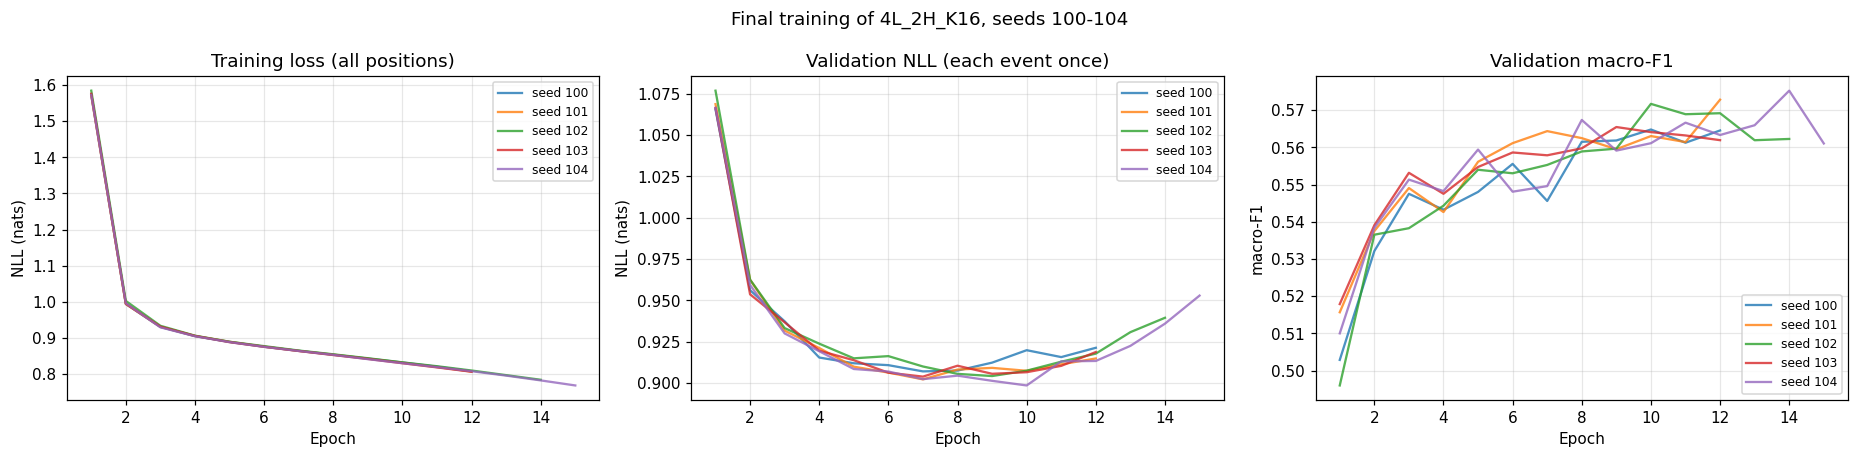

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for run_dir, seed in zip(final_runs, FINAL_SEEDS):
    history = analysis.load_history(run_dir)
    axes[0].plot(history["epoch"], history["train_loss"], alpha=0.8, label=f"seed {seed}")
    axes[1].plot(history["epoch"], history["val_nll"], alpha=0.8, label=f"seed {seed}")
    axes[2].plot(history["epoch"], history["val_macro_f1"], alpha=0.8, label=f"seed {seed}")
axes[0].set_title("Training loss (all positions)")
axes[1].set_title("Validation NLL (each event once)")
axes[2].set_title("Validation macro-F1")
for axis, label in zip(axes, ["NLL (nats)", "NLL (nats)", "macro-F1"]):
    axis.set_xlabel("Epoch")
    axis.set_ylabel(label)
    axis.legend(fontsize=8)
fig.suptitle(f"Final training of {SELECTED_LABEL}, seeds 100-104")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_4L_final_training_curves.png", bbox_inches="tight")
plt.show()

**Figure description.** Training loss, validation NLL and validation macro-F1 per epoch for the five final seeds. Training loss is averaged over all positions of each window, whereas validation NLL scores each event once with the maximum available history, so the two curves are not on exactly the same scale.

**Observation.** No run diverged. The best epochs lie between 7 and 10, and the best validation NLL of the five seeds between 0.8984 and 0.9069 (mean 0.9031, SD 0.0031). The seed SD is about three times that of the frozen 2-layer model (0.0011), so the 4-layer model varies more between seeds under the final protocol than it did in the three screening seeds (SD 0.0010).

## 2. Restricted baselines and non-neural baselines

The restricted Transformers use the selected 4-layer architecture and training settings and differ only in the information they receive:

| Model | Receives | Role |
|---|---|---|
| B5 context-only | competition, space, time, game state, history, position | value of player, team and role given context |
| B6 identity-only | player, team, role, position | value of context given identity |
| B7 role-only | everything except player and team | identity value (B7 − B8) |

The non-neural baselines B1–B3 do not depend on the Transformer architecture and are loaded from the existing Track A fit. The MLP baseline B4 is taken from Track A, because the selected context length (K = 16) equals that of the frozen Track A model and B4 is therefore evaluated on the same windows.

In [6]:
GROUPS_B5 = ["competition", "space", "time", "state", "history"]
GROUPS_B6 = ["player", "team", "role"]
GROUPS_B7 = ["role", "competition", "space", "time", "state", "history"]
restricted_runs = {"B5 context-only": [], "B6 identity-only": [], "B7 role-only": []}
for seed in BASELINE_SEEDS:
    restricted_runs["B5 context-only"].append(train_benchmark_run(transformer_config(seed, 4, SELECTED_HEADS, SELECTED_CONTEXT, GROUPS_B5)))
    restricted_runs["B6 identity-only"].append(train_benchmark_run(transformer_config(seed, 4, SELECTED_HEADS, SELECTED_CONTEXT, GROUPS_B6)))
    restricted_runs["B7 role-only"].append(train_benchmark_run(transformer_config(seed, 4, SELECTED_HEADS, SELECTED_CONTEXT, GROUPS_B7)))

with open(EXISTING_RESULTS_DIR / "04_b4_comparison.json") as handle:
    mlp_learning_rate = json.load(handle)["selected_mlp_lr"]
b4_runs = []
b4_reused = SELECTED_CONTEXT == EXISTING_FROZEN["context_length"]
for seed in [0, 1, 2]:
    b4_config = {"model_type": "mlp", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
                 "context_length": SELECTED_CONTEXT, "stride": STRIDE, "seed": seed,
                 "model": {"n_layers": 0, "n_heads": 0, "d_model": 128, "d_ff": 0, "hidden": 512, "n_previous": 3},
                 "training": {"learning_rate": mlp_learning_rate, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET}}
    existing_b4 = EXISTING_RUNS_DIR / training.run_name_for(b4_config)
    if b4_reused and (existing_b4 / "final_results.json").exists():
        b4_runs.append(existing_b4)
    else:
        b4_reused = False
        b4_runs.append(train_benchmark_run(b4_config))
print("B4 reused from Track A (read-only):", b4_reused)
neural_runs = {"B8 Transformer 4L (selected)": final_runs, "B4 MLP": b4_runs, **restricted_runs}

[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  1 | train loss 1.5994 | val NLL 1.0949 | val acc 0.5843 | val macro-F1 0.4992 | 7s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  2 | train loss 1.0303 | val NLL 0.9931 | val acc 0.5928 | val macro-F1 0.4970 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  3 | train loss 0.9647 | val NLL 0.9471 | val acc 0.6076 | val macro-F1 0.5383 | 7s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  4 | train loss 0.9368 | val NLL 0.9269 | val acc 0.6116 | val macro-F1 0.5463 | 8s
[transformer_T300_pre_action_L4_H2_D128_F512_K16_g-competition+space+time+state+history_lr0.0003_wd0.1_s100] epoch  5 | train loss 0.9217 | val NLL 0.9219 | val acc 0.6135 | val macro-F1 0.5368 | 8s
[tran

In [7]:
import shutil
import src.evaluation as evaluation
importlib.reload(evaluation)
with open(EXISTING_BASELINE_FILE) as handle:
    alphas = json.load(handle)["selected_alpha"]

encoding = data.load_encoding(ARTIFACTS_DIR / "encodings" / ENCODING)
features, _ = data.encode_features(events, encoding, POSSESSION_FEATURES)
train_rows = np.where(events["split"] == "train")[0]
val_rows = np.where(events["split"] == "val")[0]
if RUN_MODE == "smoke":
    val_rows = np.sort(final_bundle["views"]["val"]["event_rows"])
    train_rows = train_rows[:20000]

# The existing B3 checkpoint is copied into the benchmark folder before use, so that the Track A file cannot be modified.
existing_b3 = EXISTING_DIR / "artifacts_b3" / f"{ENCODING}_{POSSESSION_FEATURES}.joblib"
benchmark_b3 = BENCH_DIR / "artifacts_b3" / f"{ENCODING}_{POSSESSION_FEATURES}.joblib"
benchmark_b3.parent.mkdir(parents=True, exist_ok=True)
if existing_b3.exists() and not benchmark_b3.exists():
    shutil.copy(existing_b3, benchmark_b3)
start_time = time.time()
non_neural_predict, fitted_lr = evaluation.fit_non_neural_baselines(features, targets, train_rows, alphas,
                                                                    max_iter=1000 if RUN_MODE == "full" else 50,
                                                                    checkpoint_path=benchmark_b3)
print(f"B1-B3 ready in {time.time() - start_time:.0f} s | logistic regression iterations {fitted_lr['iterations']}, "
      f"converged {fitted_lr['converged']}")
non_neural_val_nll = {}
for name, predict in non_neural_predict.items():
    non_neural_val_nll[name] = metrics.per_event_nll(predict(val_rows), targets[val_rows])

B1-B3 ready in 1 s | logistic regression iterations 418, converged True


## 3. Selection gates on validation

The gates are those of Track A notebook 06, applied unchanged:

| Gate | Requirement | Origin of the threshold |
|---|---|---|
| Baseline improvement | the final 4-layer model beats every one of B1–B4 beyond noise on validation | Track A decision rule |
| No divergence | no final seed diverged | objective |
| Stability | seed SD of validation NLL reported; no pass/fail threshold | reported only |
| Class coverage | every class with more than 500 validation events has F1 > 0 in every seed | convention of Track A |
| Size cap | at most 4 layers and 8 heads | keeps exhaustive later analysis feasible |

In [8]:
val_rows_sorted, b8_val_nll = analysis.condition_event_nll(final_runs, targets)
val_match_ids = match_ids[val_rows_sorted]
gate_rows = []
for name, nll_fixed in non_neural_val_nll.items():
    fixed_sorted = nll_fixed[np.argsort(val_rows)][np.searchsorted(np.sort(val_rows), val_rows_sorted)]
    comparison = evaluation.compare_runs_to_fixed(b8_val_nll, fixed_sorted, val_match_ids)
    gate_rows.append({"baseline": name, "4L model - baseline NLL": comparison["difference"],
                      "CI": f"[{comparison['ci_low']:+.4f}, {comparison['ci_high']:+.4f}]",
                      "better beyond noise": comparison["better_beyond_noise"]})
b4_comparison = analysis.compare_conditions(final_runs, b4_runs, targets, match_ids)
gate_rows.append({"baseline": "B4 MLP", "4L model - baseline NLL": b4_comparison["difference_a_minus_b"],
                  "CI": f"[{b4_comparison['difference_ci_low']:+.4f}, {b4_comparison['difference_ci_high']:+.4f}]",
                  "better beyond noise": b4_comparison["a_better_beyond_noise"]})
baseline_gate_table = pd.DataFrame(gate_rows).set_index("baseline")

val_support = np.bincount(targets[val_rows_sorted], minlength=15)
coverage_failures = []
for run_dir in final_runs:
    per_class = analysis.load_final_results(run_dir)["val_metrics"]["per_class_f1"]
    for class_id in range(15):
        if val_support[class_id] > 500 and per_class[class_id] == 0:
            coverage_failures.append((run_dir.name, data.ACTION_NAMES[class_id]))
gates = {"baseline improvement (all of B1-B4)": bool(baseline_gate_table["better beyond noise"].all()),
         "no divergence": bool(not final_summary["diverged"].any()),
         "class coverage (PROVISIONAL)": len(coverage_failures) == 0,
         "size cap": frozen["model"]["n_layers"] <= 4 and frozen["model"]["n_heads"] <= 8}
print("Validation NLL across the 5 final seeds: mean", round(final_summary["val NLL"].mean(), 4),
      "| SD", round(final_summary["val NLL"].std(ddof=1), 4), "(reported, no threshold)")
for gate, passed in gates.items():
    print(f"{'PASS' if passed else 'FAIL'}  {gate}")
baseline_gate_table

Validation NLL across the 5 final seeds: mean 0.9031 | SD 0.0031 (reported, no threshold)
PASS  baseline improvement (all of B1-B4)
PASS  no divergence
PASS  class coverage (PROVISIONAL)
PASS  size cap


,4L model - baseline NLL,CI,better beyond noise
baseline,,,
B1a class prior,-1.071491,"[-1.0983, -1.0451]",True
B1b zone prior,-0.878771,"[-0.9003, -0.8566]",True
B2 Markov,-0.507776,"[-0.5211, -0.4930]",True
B3 logistic regression,-0.147641,"[-0.1545, -0.1404]",True
B4 MLP,-0.044328,"[-0.0477, -0.0409]",True


**Result.** All gates pass. The 4-layer model is better than every baseline beyond noise on validation, by 0.1476 nats against logistic regression (B3) and by 0.0443 nats against the MLP (B4). For the frozen 2-layer model, the corresponding differences were 0.1443 and 0.0410.

## 4. Primary checkpoint

As in Track A, the primary checkpoint is the final seed with the median validation NLL. The median seed represents the typical outcome of the training procedure; the best seed would select partly on chance.

In [9]:
ordered = final_summary.sort_values("val NLL").reset_index(drop=True)
primary_run_name = ordered.loc[len(ordered) // 2, "run"]
primary_seed = int(ordered.loc[len(ordered) // 2, "seed"])
print(f"Primary checkpoint: seed {primary_seed} ({primary_run_name}), validation NLL {ordered.loc[len(ordered) // 2, 'val NLL']:.4f}")

Primary checkpoint: seed 103 (transformer_T300_pre_action_L4_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s103), validation NLL 0.9038


## 5. Identity value on validation

Identity value is the validation NLL of the role-only model B7 minus that of the full model, per event and averaged. A positive value means that player and team information lowers prediction error. For the frozen Track A model this value was negative (−0.020 nats on validation), i.e. the role-only model predicted better than the full model. The same quantity is reported here for the selected 4-layer architecture. It is not used for any decision.

In [10]:
player_band, team_status = evaluation.frequency_labels(events, data.count_train_events_per_player(events),
                                                       encoding["team_vocabulary"])
identity_rows = []
groups = ["all events"] + sorted(set(player_band[val_rows_sorted]))
for group in groups:
    mask = None if group == "all events" else (player_band == group)
    comparison = analysis.compare_conditions(restricted_runs["B7 role-only"], final_runs, targets, match_ids, mask)
    identity_rows.append({"group": group, "events": comparison["n_events"], "B7 role-only NLL": comparison["nll_a_mean"],
                          "full 4L model NLL": comparison["nll_b_mean"],
                          "identity value (B7 - full)": comparison["difference_a_minus_b"],
                          "95% CI": f"[{comparison['difference_ci_low']:+.4f}, {comparison['difference_ci_high']:+.4f}]"})
identity_table = pd.DataFrame(identity_rows).set_index("group")
context_value = analysis.compare_conditions(restricted_runs["B6 identity-only"], final_runs, targets, match_ids)
identity_factors_value = analysis.compare_conditions(restricted_runs["B5 context-only"], final_runs, targets, match_ids)
print(f"B6 identity-only - full model: {context_value['difference_a_minus_b']:+.4f}")
print(f"B5 context-only - full model: {identity_factors_value['difference_a_minus_b']:+.4f}")
identity_table.round(4)

B6 identity-only - full model: +0.6722
B5 context-only - full model: -0.0062


,events,B7 role-only NLL,full 4L model NLL,identity value (B7 - full),95% CI
group,,,,,
all events,68003,0.8851,0.9031,-0.0179,"[-0.0210, -0.0150]"
100-299,20693,0.8867,0.9016,-0.0149,"[-0.0189, -0.0111]"
300-999,10644,0.8759,0.8911,-0.0152,"[-0.0214, -0.0096]"
<100 train events (incl. unseen),33419,0.8835,0.9059,-0.0223,"[-0.0262, -0.0184]"
>=1000,3247,0.9218,0.9234,-0.0016,"[-0.0188, +0.0120]"


**Result.** The identity value of the 4-layer architecture is negative: the role-only model reaches 0.8851 on validation against 0.9031 for the full model (−0.0179 nats, 95% CI −0.0210 to −0.0150). It is negative in the groups of players with fewer than 100, 100–299 and 300–999 training events (−0.0223, −0.0149, −0.0152). For players with at least 1,000 training events it is −0.0016, with an interval that includes zero. The context-only model is also better than the full model (by 0.0062 nats); the identity-only model is much worse (by 0.6722 nats).

**Interpretation.** The negative identity value found for the frozen 2-layer model (−0.0201) is also present in the 4-layer architecture, at a similar size. The additional depth does not change the finding that player and team inputs lower predictive performance under this training setup. Only for the most frequent players is the difference not distinguishable from zero.

In [11]:
validation_report = {"frozen_benchmark_config": frozen, "final_seeds": FINAL_SEEDS, "gates": gates,
                     "baseline_comparison": baseline_gate_table.reset_index().to_dict(orient="records"),
                     "coverage_failures": coverage_failures, "seed_summary": final_summary.to_dict(orient="records"),
                     "primary_run": primary_run_name, "primary_seed": primary_seed,
                     "identity_value": identity_table.reset_index().to_dict(orient="records"),
                     "b6_minus_full": context_value, "b5_minus_full": identity_factors_value,
                     "b4_reused_from_track_a": b4_reused, "run_mode": RUN_MODE}
training.save_json(RESULTS_DIR / "06_4L_validation_report.json", validation_report)
print("Validation report written before the test split is opened.")

Validation report written before the test split is opened.


## 6. Locked test evaluation

The test split is used only for the configuration recorded in benchmark notebook 05. The following models are evaluated on test for the first time:

* the selected 4-layer model (final seeds 100–104) and its restricted baselines B5–B7;
* the original 4L × 4H × K32 configuration, using the benchmark re-run (screening seeds 0–2), for the comparison in Section 7.

The test predictions of the frozen Track A model and of B1–B4 are taken from the Track A evaluation and are not recomputed.

In [12]:
test_prediction_dir = RESULTS_DIR / "test_predictions"
test_prediction_dir.mkdir(parents=True, exist_ok=True)
test_done_flag = RESULTS_DIR / "06_4L_test_results.json"

original_4l4h_runs = []
for seed in [0, 1, 2]:
    original_4l4h_runs.append(benchmark_run_dir(transformer_config(seed, 4, 4, 32)))
new_test_models = {"B8 Transformer 4L (selected)": final_runs, **restricted_runs,
                   "Original 4L4H K32 (benchmark re-run, seeds 0-2)": original_4l4h_runs}
if not b4_reused:
    new_test_models["B4 MLP"] = b4_runs

test_logits = {}
test_rows = None
if test_done_flag.exists():
    print("The test evaluation was already performed; saved benchmark predictions are reloaded.")
    for file in sorted(test_prediction_dir.glob("*.npz")):
        stored = np.load(file, allow_pickle=True)
        test_logits.setdefault(str(stored["model"]), []).append(stored["logits"])
        test_rows = stored["event_rows"]
else:
    bundles_by_context = {}
    for model_name, run_dirs in new_test_models.items():
        for run_dir in run_dirs:
            with open(run_dir / "run_config.json") as handle:
                context_length = json.load(handle)["context_length"]
            if context_length not in bundles_by_context:
                bundle = bundle_for(context_length)
                training.unlock_test_split(bundle, BENCH_DIR, events)
                bundles_by_context[context_length] = bundle
            bundle = bundles_by_context[context_length]
            model = training.load_trained_model(run_dir, bundle)
            logits, _, rows = training.predict_view(model, bundle, "test")
            order = np.argsort(rows)
            logits = logits[order]
            rows = rows[order]
            if test_rows is None:
                test_rows = rows
            assert np.array_equal(rows, test_rows), "all models must be scored on the same test events"
            test_logits.setdefault(model_name, []).append(logits)
            np.savez_compressed(test_prediction_dir / f"{run_dir.name}.npz", logits=logits, event_rows=rows,
                                model=model_name, run=run_dir.name)

# Existing Track A test predictions (read-only).
existing_test_logits = {}
for file in sorted((EXISTING_RESULTS_DIR / "test_predictions").glob("*.npz")):
    stored = np.load(file, allow_pickle=True)
    order = np.argsort(stored["event_rows"])
    rows = stored["event_rows"][order]
    assert np.array_equal(rows, test_rows), "existing and benchmark predictions must cover the same test events"
    existing_test_logits.setdefault(str(stored["model"]), []).append(stored["logits"][order])
for name in ["B1a class prior", "B1b zone prior", "B2 Markov", "B3 logistic regression"]:
    test_logits[name] = existing_test_logits[name]
if b4_reused:
    test_logits["B4 MLP"] = existing_test_logits["B4 MLP"]
test_logits["Frozen Track A model (2L, existing)"] = existing_test_logits["B8 Transformer (final)"]
test_targets = targets[test_rows]
test_match_ids = match_ids[test_rows]
print("Test events scored:", len(test_rows), "| models:", list(test_logits))

Test events scored: 65009 | models: ['B8 Transformer 4L (selected)', 'B5 context-only', 'B6 identity-only', 'B7 role-only', 'Original 4L4H K32 (benchmark re-run, seeds 0-2)', 'B1a class prior', 'B1b zone prior', 'B2 Markov', 'B3 logistic regression', 'B4 MLP', 'Frozen Track A model (2L, existing)']


### 6.1 Headline test results

For models with several seeds, the table reports the mean over seeds and the seed SD; the 95% interval of NLL is a match-level bootstrap interval computed on per-event NLL averaged over seeds.

In [13]:
model_order = ["B1a class prior", "B1b zone prior", "B2 Markov", "B3 logistic regression", "B4 MLP",
               "B6 identity-only", "B5 context-only", "B7 role-only", "Frozen Track A model (2L, existing)",
               "Original 4L4H K32 (benchmark re-run, seeds 0-2)", "B8 Transformer 4L (selected)"]
headline_rows = []
for model_name in model_order:
    seed_logits = test_logits[model_name]
    seed_metrics = []
    for logits in seed_logits:
        seed_metrics.append(metrics.compute_metrics(logits, test_targets))
    event_nll = np.mean([metrics.per_event_nll(logits, test_targets) for logits in seed_logits], axis=0)
    interval = metrics.match_bootstrap_mean(event_nll, test_match_ids, n_resamples=2000 if RUN_MODE == "full" else 50)
    nll_values = [m["nll"] for m in seed_metrics]
    headline_rows.append({"model": model_name, "seeds": len(seed_logits), "NLL": np.mean(nll_values),
                          "NLL seed SD": np.std(nll_values, ddof=1) if len(nll_values) > 1 else 0.0,
                          "NLL 95% CI": f"[{interval['ci_low']:.4f}, {interval['ci_high']:.4f}]",
                          "accuracy": np.mean([m["accuracy"] for m in seed_metrics]),
                          "top-3": np.mean([m["top3_accuracy"] for m in seed_metrics]),
                          "top-5": np.mean([m["top5_accuracy"] for m in seed_metrics]),
                          "macro-F1": np.mean([m["macro_f1"] for m in seed_metrics]),
                          "ECE": np.mean([m["ece"] for m in seed_metrics])})
headline_table = pd.DataFrame(headline_rows).set_index("model")

primary_position = [run_dir.name for run_dir in final_runs].index(primary_run_name)
primary_logits = test_logits["B8 Transformer 4L (selected)"][primary_position]
primary_metrics = metrics.compute_metrics(primary_logits, test_targets)
primary_f1_interval = metrics.match_bootstrap_macro_f1(primary_logits, test_targets, test_match_ids,
                                                       n_resamples=500 if RUN_MODE == "full" else 20)
print(f"Primary checkpoint (seed {primary_seed}) on test: NLL {primary_metrics['nll']:.4f}, accuracy "
      f"{primary_metrics['accuracy']:.4f}, macro-F1 {primary_f1_interval['mean']:.4f} "
      f"[{primary_f1_interval['ci_low']:.4f}, {primary_f1_interval['ci_high']:.4f}], ECE {primary_metrics['ece']:.4f}")
headline_table.round(4)

Primary checkpoint (seed 103) on test: NLL 0.9131, accuracy 0.6178, macro-F1 0.5590 [0.5527, 0.5654], ECE 0.0193


,seeds,NLL,NLL seed SD,NLL 95% CI,accuracy,top-3,top-5,macro-F1,ECE
model,,,,,,,,,
B1a class prior,1,2.0202,0.0000,"[1.9945, 2.0468]",0.2971,0.7163,0.8167,0.0305,0.0052
B1b zone prior,1,1.8188,0.0000,"[1.7946, 1.8444]",0.3227,0.7504,0.8702,0.1327,0.0061
B2 Markov,1,1.4332,0.0000,"[1.4108, 1.4564]",0.4489,0.8434,0.9459,0.3611,0.0048
B3 logistic regression,1,1.0649,0.0000,"[1.0451, 1.0843]",0.5753,0.9198,0.9830,0.5090,0.0122
B4 MLP,3,0.9524,0.0027,"[0.9396, 0.9652]",0.6027,0.9390,0.9920,0.5413,0.0306
B6 identity-only,3,1.7521,0.0804,"[1.6568, 1.8526]",0.3846,0.7785,0.8853,0.1968,0.0514
B5 context-only,3,0.9077,0.0043,"[0.8944, 0.9205]",0.6204,0.9450,0.9937,0.5612,0.0166
B7 role-only,3,0.8916,0.0016,"[0.8784, 0.9046]",0.6273,0.9474,0.9943,0.5694,0.0224
"Frozen Track A model (2L, existing)",5,0.9158,0.0013,"[0.9035, 0.9283]",0.6161,0.9445,0.9937,0.5580,0.0238


**Result.** On the 65,009 test events, the selected 4-layer model reaches an NLL of 0.9140 (95% CI 0.9017 to 0.9265, seed SD 0.0033), accuracy 0.6178, top-3 accuracy 0.9442, macro-F1 0.5578 and ECE 0.0255. The frozen 2-layer model reaches 0.9158 (seed SD 0.0013) and the original 4L × 4H × K32 configuration 0.9255. The restricted 4-layer models give 0.8916 (role-only), 0.9077 (context-only) and 1.7521 (identity-only).

**Interpretation.** The selected 4-layer model and the frozen 2-layer model are very close on every metric; their confidence intervals overlap almost completely, and the accuracy and macro-F1 values differ only in the third decimal. The original 4L × 4H × K32 configuration is worse than both, in line with its validation result. As on validation, the role-only and context-only models have lower test NLL than the full 4-layer model.

### 6.2 Per-class precision, recall and F1

Precision is the share of predictions of a class that are correct; recall is the share of events of a class that are predicted as that class; F1 is their harmonic mean. The table refers to the primary checkpoint.

In [14]:
from sklearn.metrics import precision_recall_fscore_support
precision, recall, f1, support = precision_recall_fscore_support(test_targets, primary_logits.argmax(axis=1),
                                                                 labels=list(range(15)), zero_division=0)
per_class_table = pd.DataFrame({"precision": precision, "recall": recall, "F1": f1, "test events": support},
                               index=data.ACTION_NAMES)
per_class_table.round(3)

,precision,recall,F1,test events
PASS_SHORT,0.515,0.522,0.519,19314
PASS_LONG,0.573,0.501,0.534,12973
CROSS,0.426,0.335,0.375,878
CARRY,0.700,0.859,0.771,14281
DRIBBLE,0.327,0.029,0.053,1170
SHOT,0.537,0.634,0.581,955
CLEARANCE,0.670,0.558,0.609,1637
RECOVERY,0.535,0.716,0.613,3861
INTERCEPTION,0.671,0.792,0.726,2202
DUEL,0.887,0.912,0.899,2667


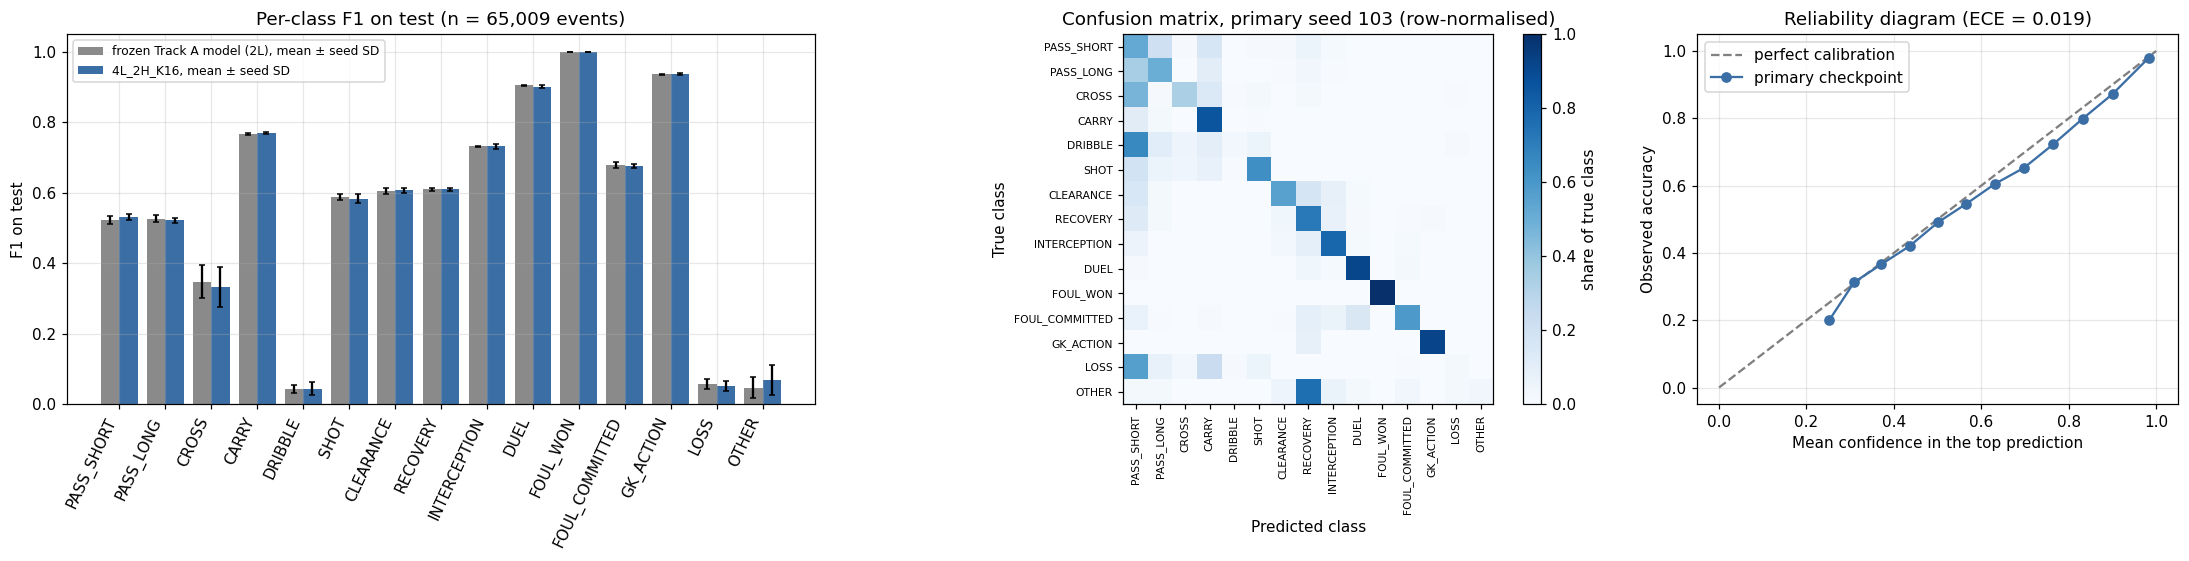

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1.4, 1.1, 0.9]})
positions = np.arange(15)
selected_f1 = np.array([metrics.compute_metrics(l, test_targets)["per_class_f1"] for l in test_logits["B8 Transformer 4L (selected)"]])
frozen_f1 = np.array([metrics.compute_metrics(l, test_targets)["per_class_f1"] for l in test_logits["Frozen Track A model (2L, existing)"]])
axes[0].bar(positions - 0.2, frozen_f1.mean(axis=0), width=0.4, yerr=frozen_f1.std(axis=0, ddof=1), capsize=2,
            color="#8a8a8a", label="frozen Track A model (2L), mean ± seed SD")
axes[0].bar(positions + 0.2, selected_f1.mean(axis=0), width=0.4, yerr=selected_f1.std(axis=0, ddof=1), capsize=2,
            color="#3b6ea5", label=f"{SELECTED_LABEL}, mean ± seed SD")
axes[0].set_xticks(positions)
axes[0].set_xticklabels(data.ACTION_NAMES, rotation=65, ha="right")
axes[0].set_ylabel("F1 on test")
axes[0].set_title(f"Per-class F1 on test (n = {len(test_rows):,} events)")
axes[0].legend(fontsize=8)

confusion_matrix = metrics.confusion(primary_logits, test_targets).astype(float)
row_sums = confusion_matrix.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
image = axes[1].imshow(confusion_matrix / row_sums, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(data.ACTION_NAMES, rotation=90, fontsize=7)
axes[1].set_yticks(positions)
axes[1].set_yticklabels(data.ACTION_NAMES, fontsize=7)
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class")
axes[1].set_title(f"Confusion matrix, primary seed {primary_seed} (row-normalised)")
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], fraction=0.046, label="share of true class")

probabilities = np.exp(metrics.log_softmax(primary_logits))
reliability = pd.DataFrame(metrics.reliability_table(probabilities, test_targets))
reliability = reliability[reliability["count"] > 0]
axes[2].plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect calibration")
axes[2].plot(reliability["mean_confidence"], reliability["accuracy"], marker="o", color="#3b6ea5", label="primary checkpoint")
axes[2].set_xlabel("Mean confidence in the top prediction")
axes[2].set_ylabel("Observed accuracy")
axes[2].set_title(f"Reliability diagram (ECE = {primary_metrics['ece']:.3f})")
axes[2].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_4L_test_class_confusion_calibration.png", bbox_inches="tight")
plt.show()

**Figure description.** Left: per-class F1 on test for the frozen Track A model and the selected 4-layer model, with seed SD as error bars. Middle: the row-normalised confusion matrix of the primary checkpoint (seed 103); row *i* shows how events of true class *i* were predicted. Right: the reliability diagram, in which points on the diagonal indicate that stated confidence equals observed accuracy.

**Observation.** The per-class F1 values of the two models are nearly identical for every class, and the error bars overlap throughout. The confusion pattern is the same as for the frozen model: DRIBBLE (F1 0.053) and LOSS (0.037) are mostly predicted as short passes or carries, OTHER (0.052) mostly as recoveries, and PASS_LONG and CROSS are frequently predicted as PASS_SHORT. The reliability diagram lies close to the diagonal (ECE 0.019 for the primary checkpoint), with slight over-confidence between confidences of about 0.5 and 0.95.

**Interpretation.** The additional depth does not change which actions the model predicts well or poorly. FOUL_WON and the goalkeeper records after goals are predicted almost deterministically for annotation reasons (Track A notebook 01, Section 8), so their F1 values do not measure modelling skill. No post-hoc calibration is applied, because the later analysis uses the raw log-probabilities.

### 6.3 Stratified test performance and robustness

In [16]:
def mean_event_nll(model_name):
    return np.mean([metrics.per_event_nll(l, test_targets) for l in test_logits[model_name]], axis=0)


nll_selected = mean_event_nll("B8 Transformer 4L (selected)")
nll_frozen = mean_event_nll("Frozen Track A model (2L, existing)")
nll_role = mean_event_nll("B7 role-only")
strata = evaluation.stratum_labels(events)
strata["player frequency"] = player_band
strata["team status"] = team_status
stratified_rows = []
for stratum_name, labels in strata.items():
    test_labels = labels[test_rows]
    for group in sorted(set(test_labels)):
        mask = test_labels == group
        stratified_rows.append({"stratum": stratum_name, "group": group, "events": int(mask.sum()),
                                "selected 4L NLL": nll_selected[mask].mean(),
                                "frozen Track A NLL": nll_frozen[mask].mean(),
                                "4L - Track A": nll_selected[mask].mean() - nll_frozen[mask].mean(),
                                "4L B7 role-only NLL": nll_role[mask].mean(),
                                "identity value (B7 - full)": nll_role[mask].mean() - nll_selected[mask].mean()})
stratified_table = pd.DataFrame(stratified_rows).set_index(["stratum", "group"])
stratified_table.round(4)

events  selected 4L NLL  frozen Track A NLL  4L - Track A  4L B7 role-only NLL  identity value (B7 - full)
stratum                group                                                                                                                                       
zone                   final third                        13052           1.0571              1.0610       -0.0039               1.0362                     -0.0209
                       middle third                       29032           0.9174              0.9189       -0.0015               0.8952                     -0.0223
                       opponent penalty box                2167           1.1358              1.1270        0.0089               1.0959                     -0.0400
                       own third                          20758           0.7962              0.7983       -0.0021               0.7743                     -0.0219
time                   0-15'                              11318           0.9096              0.9121       -0.0025               0.8898                     -0.0198
                       15-30'                             10300           0.9188              0.9217       -0.0029               0.8951                     -0.0236
                       30-45'                             10075           0.9113              0.9122       -0.0010               0.8860                     -0.0253
                       45-60'                             11257           0.9261              0.9302       -0.0042               0.9040                     -0.0221
                       60-75'                              9631           0.9027              0.9035       -0.0008               0.8836                     -0.0191
                       75'+                               12428           0.9143              0.9138        0.0004               0.8896                     -0.0247
score state            level                              32179           0.9129              0.9170       -0.0041               0.8901                     -0.0228
                       losing                             16263           0.9199              0.9200       -0.0001               0.8969                     -0.0230
                       winning                            16567           0.9104              0.9095        0.0009               0.8892                     -0.0212
possession spell       early in spell (0-2)               18650           0.9079              0.9097       -0.0018               0.8803                     -0.0276
                       first event of period                 70           0.4130              0.4092        0.0039               0.3910                     -0.0221
                       long spell (10+)                   20387           0.9086              0.9111       -0.0025               0.8878                     -0.0208
                       mid spell (3-9)                    25902           0.9241              0.9254       -0.0013               0.9040                     -0.0201
turnover of actor team acting team changed                16596           0.8169              0.8208       -0.0040               0.7971                     -0.0197
                       same acting team                   48413           0.9474              0.9484       -0.0011               0.9239                     -0.0234
coupled                genuine sequence event             58115           1.0028              1.0046       -0.0018               0.9790                     -0.0238
                       same-moment (coupled) event         6894           0.1660              0.1680       -0.0020               0.1547                     -0.0113
player frequency       100-299                            21686           0.9141              0.9164       -0.0023               0.8946                     -0.0195
                       300-999                            10816           0.9202              0.9222       -0.0020       

In [17]:
genuine = strata["coupled"][test_rows] == "genuine sequence event"
robustness_rows = {}
for model_name in ["B3 logistic regression", "B4 MLP", "B7 role-only", "Frozen Track A model (2L, existing)",
                   "Original 4L4H K32 (benchmark re-run, seeds 0-2)", "B8 Transformer 4L (selected)"]:
    seed_values = []
    for logits in test_logits[model_name]:
        seed_values.append(metrics.compute_metrics(logits[genuine], test_targets[genuine]))
    robustness_rows[model_name] = {"NLL (genuine events only)": np.mean([m["nll"] for m in seed_values]),
                                   "accuracy (genuine only)": np.mean([m["accuracy"] for m in seed_values]),
                                   "macro-F1 (genuine only)": np.mean([m["macro_f1"] for m in seed_values])}
robustness_table = pd.DataFrame(robustness_rows).T
print(f"Genuine sequence events: {genuine.sum():,} of {len(genuine):,} test events")
robustness_table.round(4)

Genuine sequence events: 58,115 of 65,009 test events


,NLL (genuine events only),accuracy (genuine only),macro-F1 (genuine only)
B3 logistic regression,1.1449,0.5370,0.4143
B4 MLP,1.0439,0.5632,0.4598
B7 role-only,0.9790,0.5898,0.4878
"Frozen Track A model (2L, existing)",1.0046,0.5775,0.4763
"Original 4L4H K32 (benchmark re-run, seeds 0-2)",1.0144,0.5745,0.4681
B8 Transformer 4L (selected),1.0028,0.5796,0.4770


**Observation.** Across all 27 strata, the difference between the selected 4-layer model and the frozen 2-layer model lies between −0.0042 and +0.0089 nats. It is slightly negative in most strata, and the largest positive value (+0.0089, 4-layer worse) is in the opponent penalty box, the smallest zone group (2,167 events). The identity value is negative in every stratum, between −0.0113 (coupled events) and −0.0400 (opponent penalty box).

Without same-moment (coupled) events, the test NLL is 0.9790 for the role-only model, 1.0028 for the selected 4-layer model, 1.0046 for the frozen 2-layer model, 1.0144 for the original 4L × 4H × K32 configuration, 1.0439 for the MLP and 1.1449 for logistic regression. The ordering is the same as on all events.

**Interpretation.** The small overall advantage of the 4-layer model is spread thinly over the strata rather than concentrated in a particular game situation. The conclusions, including the negative identity value, do not depend on the annotation-coupled events.

## 7. Final comparison: frozen Track A model, original 4L × 4H and selected 4-layer model

The table separates validation results, which were used for selection, from test results, which were not. The original 4L × 4H row uses the benchmark re-run with screening seeds 0–2, because this configuration was not trained under the final five-seed protocol; its test values are therefore based on three seeds and are shown for comparison only.

In [18]:
def cost_and_validation(run_dirs):
    records = []
    for run_dir in run_dirs:
        records.append(run_record(run_dir, "", ""))
    table = pd.DataFrame(records)
    return {"validation NLL (selection evidence)": table["val_nll"].mean(),
            "validation NLL SD": table["val_nll"].std(ddof=1),
            "training minutes per run": table["training_minutes"].mean(), "parameters": int(table["parameters"].iloc[0])}


frozen_model = EXISTING_FROZEN["model"]
frozen_final_runs = []
for seed in FINAL_SEEDS:
    frozen_final_runs.append(existing_run_dir(transformer_config(seed, frozen_model["n_layers"], frozen_model["n_heads"],
                                                                 EXISTING_FROZEN["context_length"])))
comparison_rows = []
for label, name, layers, heads, context_length, run_dirs, seed_note in [
        ("Existing Track A model (frozen)", "Frozen Track A model (2L, existing)", frozen_model["n_layers"],
         frozen_model["n_heads"], EXISTING_FROZEN["context_length"], frozen_final_runs, "final seeds 100-104"),
        ("Original 4L4H model (benchmark re-run)", "Original 4L4H K32 (benchmark re-run, seeds 0-2)", 4, 4, 32,
         original_4l4h_runs, "screening seeds 0-2"),
        ("Selected 4-layer benchmark model", "B8 Transformer 4L (selected)", 4, SELECTED_HEADS, SELECTED_CONTEXT,
         final_runs, "final seeds 100-104")]:
    row = {"model": label, "seeds": seed_note, "layers": layers, "heads": heads, "d_head": D_MODEL // heads,
           "K": context_length}
    row.update(cost_and_validation(run_dirs))
    headline = headline_table.loc[name]
    row["test NLL"] = headline["NLL"]
    row["test NLL seed SD"] = headline["NLL seed SD"]
    row["test NLL 95% CI"] = headline["NLL 95% CI"]
    row["test accuracy"] = headline["accuracy"]
    row["test top-3"] = headline["top-3"]
    row["test top-5"] = headline["top-5"]
    row["test macro-F1"] = headline["macro-F1"]
    row["test ECE"] = headline["ECE"]
    row["test NLL, genuine events only (robustness)"] = robustness_table.loc[name, "NLL (genuine events only)"]
    comparison_rows.append(row)
final_comparison = pd.DataFrame(comparison_rows).set_index("model")
final_comparison.to_csv(RESULTS_DIR / "06_4L_final_comparison.csv")

paired_difference = nll_selected - nll_frozen
paired_interval = metrics.match_bootstrap_mean(paired_difference, test_match_ids,
                                               n_resamples=2000 if RUN_MODE == "full" else 50)
print(f"Test NLL difference, selected 4L model - frozen Track A model (seed-averaged, paired): "
      f"{paired_interval['mean']:+.4f} (95% match-bootstrap CI {paired_interval['ci_low']:+.4f} to "
      f"{paired_interval['ci_high']:+.4f}). Reported for description only; not used for selection.")
final_comparison.T

Test NLL difference, selected 4L model - frozen Track A model (seed-averaged, paired): -0.0018 (95% match-bootstrap CI -0.0035 to -0.0001). Reported for description only; not used for selection.


model,Existing Track A model (frozen),Original 4L4H model (benchmark re-run),Selected 4-layer benchmark model
seeds,final seeds 100-104,screening seeds 0-2,final seeds 100-104
layers,2,4,4
heads,2,4,2
d_head,64,32,64
K,16,32,16
validation NLL (selection evidence),0.906456,0.914559,0.903078
validation NLL SD,0.001105,0.005176,0.003126
training minutes per run,1.027891,1.746324,1.818892
parameters,514575,913167,911119
test NLL,0.915847,0.925474,0.914042


**Reading the table.** The column "validation NLL (selection evidence)" contains the values on which the selection in benchmark notebook 05 was based (screening seeds for the original 4L × 4H model, final seeds for the other two). All columns beginning with "test" were computed after the selection was frozen. The paired test difference between the selected 4-layer model and the frozen Track A model is reported as a description of the test outcome. It is not used to revise the selection or the replacement assessment, both of which were recorded before the test split was opened.

**Result.** The selected 4-layer model has a test NLL 0.0018 nats lower than the frozen 2-layer model (paired 95% CI −0.0035 to −0.0001). Accuracy (0.6178 against 0.6161), top-3 and top-5 accuracy and macro-F1 (0.5578 against 0.5580) are practically equal, and the ECE is slightly higher for the 4-layer model (0.0255 against 0.0238). The 4-layer model has 1.77 times as many parameters, takes about 1.8 times as long to train per run, and varies more between seeds (test seed SD 0.0033 against 0.0013). The original 4L × 4H × K32 configuration is the weakest of the three on every test metric (NLL 0.9255).

**Interpretation.** The validation advantage of the 4-layer model over the frozen 2-layer model carries over to the test split in direction, but it is smaller (0.0018 against 0.0034 on validation with final seeds) and of the same size as the seed standard deviation of the 4-layer model. The interval only just excludes zero. The test result is consistent with a very small predictive benefit of the additional depth, and does not show a benefit in accuracy, macro-F1 or calibration.

In [19]:
test_results = {"run_mode": RUN_MODE, "frozen_benchmark_config": frozen, "primary_run": primary_run_name,
                "primary_seed": primary_seed, "n_test_events": int(len(test_rows)),
                "headline": headline_table.reset_index().to_dict(orient="records"),
                "primary_checkpoint_metrics": primary_metrics, "primary_macro_f1_ci": primary_f1_interval,
                "per_class": per_class_table.reset_index().to_dict(orient="records"),
                "stratified": stratified_table.reset_index().to_dict(orient="records"),
                "robustness_genuine_events_only": robustness_table.reset_index().to_dict(orient="records"),
                "final_comparison": final_comparison.reset_index().to_dict(orient="records"),
                "paired_test_difference_selected_minus_frozen": paired_interval}
if not test_done_flag.exists():
    training.save_json(test_done_flag, test_results)
    print("Test results saved:", test_done_flag)
else:
    print("The test results were saved at the first evaluation and are not overwritten.")

Test results saved: /content/drive/MyDrive/soccer_mi/track_a/benchmarks/track_a_4layer/results/06_4L_test_results.json


## 8. Integrity check of the Track A reference results

The fingerprints of the Track A result and configuration files, recorded before the benchmark started, are compared with their current state. All 35 files are unchanged, so the Track A results used as reference in this benchmark were not modified by it.

In [20]:
with open(MANIFEST_DIR / "existing_results_snapshot.json") as handle:
    snapshot = json.load(handle)
changed = []
missing = []
for relative_path, fingerprint in snapshot.items():
    path = EXISTING_DIR / relative_path
    if not path.exists():
        missing.append(relative_path)
    elif file_sha256(path) != fingerprint:
        changed.append(relative_path)
print(f"Existing Track A files checked: {len(snapshot)} | changed: {len(changed)} | missing: {len(missing)}")
if changed or missing:
    print("Changed:", changed)
    print("Missing:", missing)

Existing Track A files checked: 35 | changed: 0 | missing: 0


## 9. Research interpretation

The evidence cell below collects, for each research question, the quantities on which the answer rests. The answers follow after it.

In [21]:
evidence = {}
depth_file = RESULTS_DIR / "05_4L_vs_2L_matched.csv"
if depth_file.exists():
    evidence["1. depth 2 -> 4 (matched validation comparisons)"] = pd.read_csv(depth_file).to_dict(orient="records")
evidence["2. head count within 4 layers"] = pd.read_csv(RESULTS_DIR / "05_4L_head_comparison.csv").to_dict(orient="records")
evidence["3. context length within 4 layers"] = pd.read_csv(RESULTS_DIR / "05_4L_context_comparison.csv").to_dict(orient="records")
evidence["2-3. two-way analysis"] = pd.read_csv(RESULTS_DIR / "05_4L_two_way_analysis.csv").to_dict(orient="records")
evidence["4. original 4L4H (validation and test)"] = final_comparison.loc["Original 4L4H model (benchmark re-run)"].to_dict()
evidence["5. stability of the selected model (final seeds)"] = {"validation NLL SD": float(final_summary["val NLL"].std(ddof=1)),
                                                                "test NLL seed SD": float(headline_table.loc["B8 Transformer 4L (selected)", "NLL seed SD"])}
evidence["6. selected 4L vs frozen Track A"] = {"replacement assessment (validation)": frozen["replacement_assessment"],
                                                "paired test difference": paired_interval}
evidence["7. MI substrate"] = pd.read_csv(RESULTS_DIR / "05_4L_mi_feasibility.csv").to_dict(orient="records")
evidence["identity value of the selected architecture (validation)"] = identity_table.loc["all events"].to_dict()
training.save_json(RESULTS_DIR / "06_4L_interpretation_evidence.json", evidence)
for question, content in evidence.items():
    print(question)
    print("   ", str(content)[:400])

1. depth 2 -> 4 (matched validation comparisons)
    [{'heads': 2, 'K': 16, 'lower NLL': '4L_2H_K16', 'gap (higher - lower NLL)': 0.0049165892414748, '95% CI of gap': '[0.0025, 0.0073]', 'seeds separated': True, 'beyond noise': True, '2-layer seeds available': 3}, {'heads': 2, 'K': 32, 'lower NLL': '4L_2H_K32', 'gap (higher - lower NLL)': 0.004374744836241, '95% CI of gap': '[0.0025, 0.0063]', 'seeds separated': False, 'beyond noise': False, '2-laye
2. head count within 4 layers
    [{'K': 16, 'comparison': '4L_2H_K16 vs 4L_4H_K16', 'gap (higher - lower NLL)': 0.0015078092692419, '95% CI of gap': '[-0.0004, 0.0035]', 'seeds separated': False, 'beyond noise': False}, {'K': 16, 'comparison': '4L_2H_K16 vs 4L_8H_K16', 'gap (higher - lower NLL)': 0.0033738545607775, '95% CI of gap': '[0.0013, 0.0055]', 'seeds separated': False, 'beyond noise': False}, {'K': 32, 'comparison': '4L_
3. context length within 4 layers
    [{'heads': 2, 'comparison': '4L_2H_K16 vs 4L_2H_K32', 'gap (higher - lowe

**1. Does increasing depth from 2 to 4 provide a meaningful predictive improvement?** The improvement is consistent but small. At matched head count and context length, 4 layers have the lower validation NLL in four of five comparisons, beyond noise in two of them (0.0049 nats at 2 heads, K = 16; 0.0042 at 8 heads, K = 32), and no advantage at K = 64. On test, the selected 4-layer model is better than the frozen 2-layer model by 0.0018 nats, with an interval that only just excludes zero, and with no difference in accuracy, macro-F1 or calibration. The additional depth improves the probabilistic fit slightly; the evidence does not show a practically meaningful improvement in prediction.

**2. Does the head count matter within the 4-layer family?** Not to a degree the experiment can resolve. The head count explains little variation (F = 1.54, p = 0.24), and within a context length the head counts differ by at most 0.0034 nats. Only one of six comparisons meets the decision rule (2 heads better than 8 heads at K = 32). Two heads have the lowest mean at K = 16 and K = 32.

**3. Does the context length matter within the 4-layer family?** Yes. It is the dominant architectural factor (F = 272.3). For every head count, K = 16 is better than K = 32 by about 0.010 nats and better than K = 64 by about 0.026–0.029 nats, with complete seed separation. Longer windows also reach their best epoch earlier and overfit faster. The same direction was found at 2 layers in Track A.

**4. Does the original 4L × 4H architecture remain scientifically justified?** Not as the preferred configuration under this training setup. Its re-run reproduces the Track A record exactly (0.9146), but it is beaten beyond noise by the selected 4L × 2H × K16 on validation (by 0.0121 nats), has the largest seed variation in the grid (SD 0.0052), and is the weakest of the three compared models on test (0.9255). The comparison indicates that its main disadvantage is the context length of 32; its head count makes little difference.

**5. Is the selected 4-layer model sufficiently stable across seeds?** Training is stable: no run diverged and all gates pass. The variation between seeds is, however, larger than for the frozen 2-layer model (final-seed SD 0.0031 on validation and 0.0033 on test, against 0.0011 and 0.0013). This variation is of the same size as the test difference between the two models, so single-seed comparisons between them would not be reliable.

**6. How does it compare with the existing 2-layer model?** It is slightly better in NLL (validation 0.9031 against 0.9065 on final seeds; test 0.9140 against 0.9158) and equal in accuracy, macro-F1 and per-class behaviour. It has 1.77 times as many parameters, trains about 1.8 times as long per run and varies more between seeds. Both models share the negative identity value: in both architectures the role-only model predicts better than the full model (4-layer identity value −0.0179 on validation).

**7. Does the selected architecture provide a better substrate for the planned MI experiments?** In one respect it does: four layers allow attention compositions across three layer boundaries instead of one, which is required for hypotheses involving more than one stage of attention-based routing. With 2 heads per layer (8 heads, 24 head-pair paths, about 1.4 GB of cached activations for the validation split), it remains small enough for exhaustive analysis. Predictively, the two architectures are almost equivalent, so the choice rests on whether the planned hypotheses require multi-stage composition. For the identity-versus-context question specifically, neither architecture uses identity to predictive advantage, and the additional depth does not change this.

**8. What remains uncertain?** Three screening seeds give only a coarse estimate of seed variation, and the final-seed variation of the 4-layer model turned out larger than in screening. The learning rate and weight decay were tuned on a different configuration (4L × 4H × K32, T100), which may disadvantage some configurations. The reason why shorter windows predict better, and why longer windows overfit sooner, is not isolated. The cause of the negative identity value is not established. The test split was used for the second time. The decision rule and the simplicity order are conventions of this study.

## 10. Limitations

* The test split was used a second time. The selection and the replacement assessment were recorded before this evaluation, but the Track A test results were known when the benchmark was designed.
* The original 4L × 4H configuration is compared on test with three screening seeds, while the other two models use five final seeds.
* The identity value of the frozen Track A model was negative on validation and test; the corresponding value for the selected 4-layer architecture is reported in Section 5. A negative identity value affects the identity-versus-context research question independently of the architecture.
* The possession inputs are the pre-action versions of Track A notebook 01; the corrections proposed by the temporal provenance audit are not applied. They are identical across all models compared here.